# Validate J from psi against pySECS J

Self-contained step-by-step test using the existing data, the cubed-sphere pole grid, and the shifted evaluation grid from `set_up_secs.py`.

## 0. Missing-data weighting test

Check that entries masked with `obs_std = inf` are truly excluded from the fit. Perturb one masked observation and confirm the SECS amplitudes do not change. A finite-weight control perturbation should change them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pysecs import secs

from set_up_secs import SECSFit

np.set_printoptions(precision=4, suppress=True, linewidth=160)

NOTEBOOK_DIR = Path.cwd()
DATA_PATH = (
    NOTEBOOK_DIR.parent
    / 'data'
    / 'all_stations'
    / 'SuperMAG_60s_20231201_rev-0006.1783148935.netcdf'
)

probe = SECSFit(DATA_PATH)
probe._make_observations()
probe._make_grid()

missing = ~np.isfinite(probe.dbn) | ~np.isfinite(probe.dbe)
if np.any(missing):
    time_index, station_index = np.argwhere(missing)[0]
    component_index = (
        0 if not np.isfinite(probe.dbn[time_index, station_index]) else 1
    )
else:
    time_index, station_index, component_index = 0, 0, 0
    probe.obs_std[time_index, station_index, component_index] = np.inf
    print('No naturally missing horizontal observation; masked one manually.')

base_obs_B = probe.obs_B[time_index : time_index + 1].copy()
base_obs_std = probe.obs_std[time_index : time_index + 1].copy()


def snapshot_sec_amps(obs_B):
    model = secs.SECS(sec_df_loc=probe.pole_loc)
    model.fit(
        probe.obs_loc,
        obs_B,
        obs_std=base_obs_std,
        epsilon=probe.epsilon,
    )
    return model.sec_amps


base_amps = snapshot_sec_amps(base_obs_B)

masked_obs_B = base_obs_B.copy()
masked_obs_B[0, station_index, component_index] += 1e-7
masked_amps = snapshot_sec_amps(masked_obs_B)
masked_difference = np.max(np.abs(masked_amps - base_amps))

finite_horizontal = np.argwhere(
    np.isfinite(probe.obs_std[time_index, :, :2])
)
control_difference = np.nan
if finite_horizontal.size:
    control_station, control_component = finite_horizontal[0]
    control_obs_B = base_obs_B.copy()
    control_obs_B[0, control_station, control_component] += 1e-7
    control_amps = snapshot_sec_amps(control_obs_B)
    control_difference = np.max(np.abs(control_amps - base_amps))

print('test time:', probe.times[time_index])
print('masked station index:', station_index)
print('masked component:', 'north' if component_index == 0 else 'east')
print('masked obs_std:', base_obs_std[0, station_index, component_index])
print('masked perturbation max |delta sec_amps|:', masked_difference)
print('finite-weight control max |delta sec_amps|:', control_difference)
print(
    'PASS: masked entry is excluded and finite-weight entry affects the fit'
    if masked_difference < 1e-12 and control_difference > 0.0
    else 'CHECK: masking behavior is not as expected'
)

No naturally missing horizontal observation; masked one manually.
test time: 2023-12-01 00:00:00+00:00
masked station index: 0
masked component: north
masked obs_std: inf
masked perturbation max |delta sec_amps|: 0.0
finite-weight control max |delta sec_amps|: 9293.164534569303
PASS: masked entry is excluded and finite-weight entry affects the fit


## 1. Load data, fit pySECS, and inspect amplitudes, J, and B

In [2]:

def print_head(name, array, rows=10, cols=5):
    print(f'{name} shape: {array.shape}')
    print(f'{name} head({rows}) [first {cols} points/columns]:')
    print(array[(slice(0, rows),) + (slice(0, cols),) * (array.ndim - 1)])
    print()


fit = SECSFit(DATA_PATH).fit()

print('data:', Path(fit.fpath).relative_to(NOTEBOOK_DIR.parent))
print('times:', fit.times.shape)
print('observations:', fit.obs_loc.shape)
print('pole grid:', fit.pole_grid.shape)
print('pole points:', fit.pole_loc.shape)
print('eval grid:', fit.eval_grid.shape)
print('eval points:', fit.eval_loc.shape)
print()

print_head('sec_amps', fit.sec_amps)
print_head('J', fit.J)
print_head('B', fit.B)

data: data/all_stations/SuperMAG_60s_20231201_rev-0006.1783148935.netcdf
times: (1440,)
observations: (105, 3)
pole grid: (28, 28)
pole points: (624, 3)
eval grid: (25, 25)
eval points: (440, 3)

sec_amps shape: (1440, 624)
sec_amps head(10) [first 5 points/columns]:
[[ 994.7485 1545.7707 2129.0006 2767.657  7187.1376]
 [1031.3905 1556.7639 2112.2647 2723.7659 7391.0473]
 [ 986.9904 1479.9279 2002.9317 2583.2304 7064.1302]
 [1074.5644 1498.8267 1959.6277 2482.8695 6815.5681]
 [1234.2067 1689.4838 2184.7834 2741.7618 7481.3761]
 [1127.3875 1638.2446 2189.794  2805.5255 6784.0853]
 [1098.9439 1688.4961 2314.7849 3000.1472 7073.2262]
 [ 984.3847 1658.3474 2360.5399 3115.2392 6981.7304]
 [ 917.8573 1577.0227 2261.9147 3000.3808 6769.9354]
 [ 899.4727 1620.5556 2357.7872 3137.7511 6987.0355]]

J shape: (1440, 440, 2)
J head(10) [first 5 points/columns]:
[[[-0.0155  0.0034]
  [-0.0064 -0.0067]
  [-0.0041 -0.0167]
  [-0.0035 -0.0216]
  [-0.0036 -0.0226]]

 [[-0.0151  0.0032]
  [-0.0059 -0.006

## 2. Predict psi on the evaluation grid

In [3]:
psi = fit.predict_psi()

print_head('psi', psi)
print('finite psi:', np.isfinite(psi).sum(), '/', psi.size)
print('psi min:', np.nanmin(psi))
print('psi max:', np.nanmax(psi))

psi shape: (1440, 440)
psi head(10) [first 5 points/columns]:
[[-40083.4757 -40739.2354 -37781.0788 -32565.547  -26438.6465]
 [-38450.0117 -39044.4883 -36086.826  -30939.9271 -24955.4862]
 [-38798.1025 -39301.0359 -36347.6994 -31271.3301 -25405.9927]
 [-37753.6547 -38149.2598 -35281.3124 -30433.1403 -24893.5435]
 [-38707.1515 -38935.0408 -35817.641  -30656.981  -24744.2009]
 [-39491.6145 -39893.5847 -37121.0046 -32348.7199 -26747.0151]
 [-39992.5117 -40330.7793 -37268.5594 -32046.6875 -25893.4219]
 [-42167.1694 -42492.1811 -39166.7763 -33491.677  -26775.0995]
 [-41752.2206 -42154.0282 -38815.0201 -33085.8072 -26345.0844]
 [-42267.1662 -42461.7336 -38644.342  -32248.2552 -24761.1218]]

finite psi: 633600 / 633600
psi min: -2336850.5306383893
psi max: 907313.6388159388


## 3. Build J from psi and compare with predict_J

In [4]:
def current_metrics(reference, reconstructed):
    difference = reconstructed - reference
    valid = np.isfinite(reference).all(axis=-1) & np.isfinite(
        reconstructed
    ).all(axis=-1)

    metrics = {
        'difference': difference,
        'valid': valid,
        'max_abs': np.nan,
        'rms': np.nan,
        'correlation': np.nan,
        'components': {},
    }
    if not np.any(valid):
        return metrics

    values = difference[valid]
    metrics['max_abs'] = float(np.max(np.abs(values)))
    metrics['rms'] = float(np.sqrt(np.mean(values**2)))

    ref = reference[valid]
    rec = reconstructed[valid]
    if np.std(ref) > 0.0 and np.std(rec) > 0.0:
        metrics['correlation'] = float(
            np.corrcoef(ref.ravel(), rec.ravel())[0, 1]
        )

    for index, name in enumerate(('east', 'north')):
        component_difference = difference[..., index][valid]
        component_reference = reference[..., index][valid]
        component_reconstructed = reconstructed[..., index][valid]
        component = {
            'max_abs': float(np.max(np.abs(component_difference))),
            'rms': float(np.sqrt(np.mean(component_difference**2))),
        }
        if (
            np.std(component_reference) > 0.0
            and np.std(component_reconstructed) > 0.0
        ):
            component['correlation'] = float(
                np.corrcoef(
                    component_reference.ravel(),
                    component_reconstructed.ravel(),
                )[0, 1]
            )
        metrics['components'][name] = component

    return metrics


J_from_psi = fit.predict_J_from_psi(psi)
metrics = current_metrics(fit.J, J_from_psi)

print_head('J_from_psi', J_from_psi)
print_head('J_from_psi - J', metrics['difference'])
print(
    'valid comparison points:',
    metrics['valid'].sum(),
    '/',
    metrics['valid'].size,
)
print('max |J_from_psi - J| [A/m]:', metrics['max_abs'])
print('rms |J_from_psi - J| [A/m]:', metrics['rms'])
print('correlation:', metrics['correlation'])
print()
for name, component in metrics['components'].items():
    print(name, 'max_abs [A/m]:', component['max_abs'])
    print(name, 'rms [A/m]:', component['rms'])
    print(name, 'correlation:', component.get('correlation', np.nan))

J_from_psi shape: (1440, 440, 2)
J_from_psi head(10) [first 5 points/columns]:
[[[-0.0162  0.0025]
  [-0.0077 -0.0063]
  [-0.0038 -0.0175]
  [-0.0033 -0.0209]
  [-0.0032 -0.0233]]

 [[-0.0157  0.0023]
  [-0.0071 -0.0063]
  [-0.0031 -0.0172]
  [-0.0025 -0.0204]
  [-0.0024 -0.0226]]

 [[-0.0153  0.002 ]
  [-0.007  -0.0064]
  [-0.0029 -0.017 ]
  [-0.0021 -0.02  ]
  [-0.0018 -0.022 ]]

 [[-0.0148  0.0016]
  [-0.0072 -0.0065]
  [-0.0031 -0.0164]
  [-0.002  -0.019 ]
  [-0.0015 -0.0207]]

 [[-0.0157  0.0007]
  [-0.0077 -0.0074]
  [-0.0038 -0.0176]
  [-0.0029 -0.0203]
  [-0.0027 -0.0222]]

 [[-0.0154  0.0011]
  [-0.0078 -0.0064]
  [-0.0044 -0.0163]
  [-0.0042 -0.0192]
  [-0.0045 -0.0215]]

 [[-0.0158  0.001 ]
  [-0.0076 -0.007 ]
  [-0.0043 -0.0177]
  [-0.0043 -0.021 ]
  [-0.0048 -0.0236]]

 [[-0.0162  0.0012]
  [-0.0074 -0.0075]
  [-0.0041 -0.019 ]
  [-0.0042 -0.0229]
  [-0.0048 -0.0258]]

 [[-0.0158  0.0019]
  [-0.0071 -0.0073]
  [-0.0034 -0.0191]
  [-0.0032 -0.0229]
  [-0.0034 -0.0257]]

 [[

## 4. Jx and Jy scatter comparison

The x axis is the pySECS `predict_J` result and the y axis is `psi_to_J`.

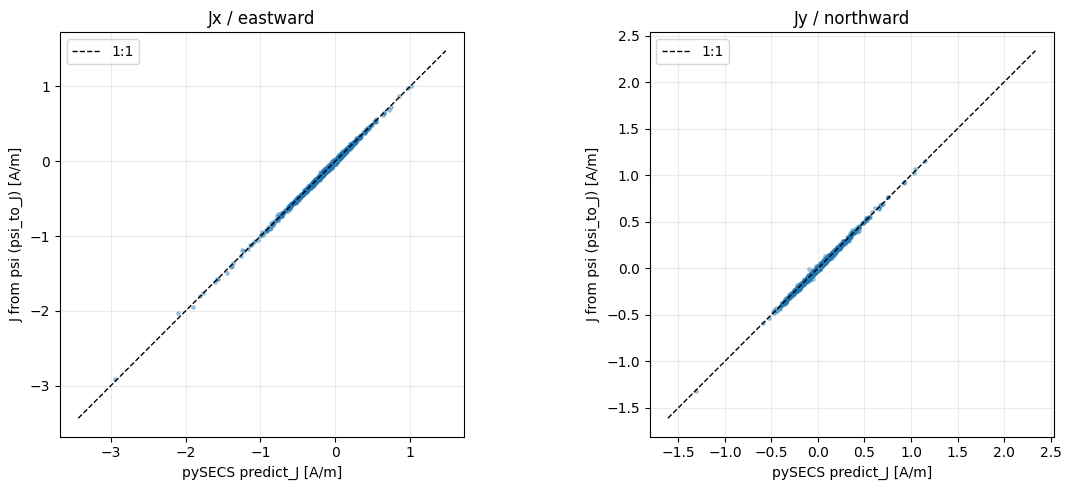

In [5]:
valid = metrics['valid']
component_names = ('Jx / eastward', 'Jy / northward')
sample_size = 5000

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for index, (ax, name) in enumerate(zip(axes, component_names)):
    reference = fit.J[..., index][valid]
    reconstructed = J_from_psi[..., index][valid]
    count = reference.size
    indices = np.linspace(0, count - 1, min(count, sample_size), dtype=int)

    ax.scatter(
        reference[indices],
        reconstructed[indices],
        s=6,
        alpha=0.35,
        color='tab:blue',
    )
    low = min(reference.min(), reconstructed.min())
    high = max(reference.max(), reconstructed.max())
    ax.plot([low, high], [low, high], 'k--', lw=1, label='1:1')
    ax.set_xlabel('pySECS predict_J [A/m]')
    ax.set_ylabel('J from psi (psi_to_J) [A/m]')
    ax.set_title(name)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

## 5. Singular-value spectrum and J regularization sensitivity

Use the frame with the largest predicted current for these diagnostics. The singular-value spectrum shows how many independent constraints the observations provide, while the comparisons show how `predict_J` changes with `epsilon` and with coarser SEC grids.


diagnostic frame: 675 2023-12-01 11:15:00+00:00
horizontal observations: 210
SEC amplitudes: 624
maximum possible rank: 210
numerical rank: 210

 epsilon  retained_rank
    0.01            133
    0.02            121
    0.05             91
    0.10             46
    0.20             16
    0.50              3


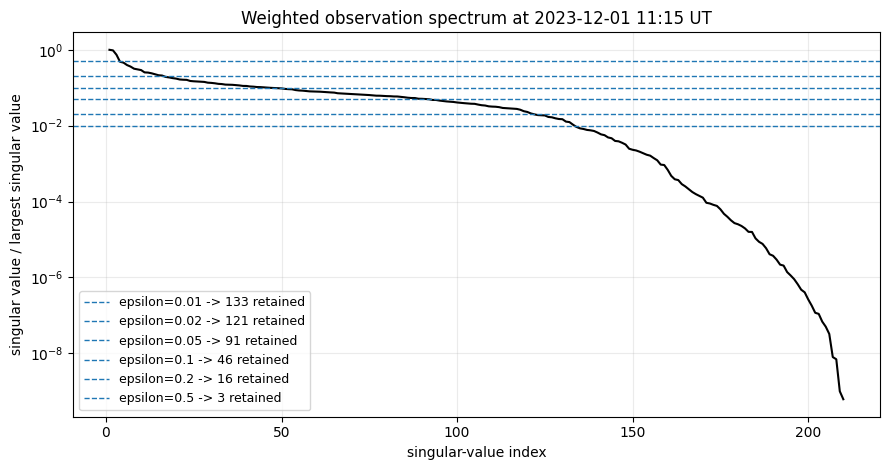

In [6]:
import pandas as pd


def east_north_current(model, evaluation_locations):
    model_current = np.asarray(model.predict_J(evaluation_locations))
    if model_current.ndim == 2:
        model_current = model_current[np.newaxis, ...]
    return model_current[0][..., [1, 0]]


frame_current_magnitude = np.hypot(fit.J[..., 0], fit.J[..., 1])
diagnostic_frame_index = int(
    np.argmax(np.max(frame_current_magnitude, axis=1))
)
diagnostic_timestamp = pd.Timestamp(fit.times[diagnostic_frame_index])

transfer_matrix = secs.T_df(
    obs_loc=fit.obs_loc,
    sec_loc=fit.pole_loc,
)
observation_weights = fit.obs_std[diagnostic_frame_index].reshape(-1)
finite_observation_weights = np.isfinite(observation_weights)
weighted_transfer = (
    transfer_matrix.reshape(-1, fit.pole_loc.shape[0])[
        finite_observation_weights
    ]
    / observation_weights[finite_observation_weights, None]
)

singular_values = np.linalg.svd(
    weighted_transfer,
    compute_uv=False,
)
relative_singular_values = singular_values / singular_values[0]
epsilon_values = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.5])
retained_ranks = np.array(
    [
        int(np.sum(relative_singular_values >= epsilon))
        for epsilon in epsilon_values
    ]
)

print('diagnostic frame:', diagnostic_frame_index, diagnostic_timestamp)
print('horizontal observations:', weighted_transfer.shape[0])
print('SEC amplitudes:', weighted_transfer.shape[1])
print('maximum possible rank:', min(weighted_transfer.shape))
print('numerical rank:', int(np.sum(singular_values > 0.0)))
print()
print(
    pd.DataFrame(
        {
            'epsilon': epsilon_values,
            'retained_rank': retained_ranks,
        }
    ).to_string(index=False)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogy(
    np.arange(1, singular_values.size + 1),
    relative_singular_values,
    color='black',
    lw=1.5,
)
for epsilon, retained_rank in zip(epsilon_values, retained_ranks):
    ax.axhline(
        epsilon,
        linestyle='--',
        lw=1,
        label=f'epsilon={epsilon:g} -> {retained_rank} retained',
    )
ax.set_xlabel('singular-value index')
ax.set_ylabel('singular value / largest singular value')
ax.set_title(
    f'Weighted observation spectrum at {diagnostic_timestamp:%Y-%m-%d %H:%M UT}'
)
ax.grid(alpha=0.25, which='both')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


J sensitivity to epsilon on the baseline SEC grid:
 epsilon    max_mA_m  median_mA_m    p99_mA_m  corr_vs_eps_0.05  relative_rms_vs_eps_0.05
    0.01 4036.001809   322.002841 2393.266944          0.933776              3.788244e-01
    0.02 3844.205395   333.736262 2279.740355          0.955543              2.873670e-01
    0.05 3733.928524   307.349824 2262.794033          1.000000              4.827993e-16
    0.10 2720.200630   273.362102 2285.938600          0.916265              3.766781e-01
    0.20 1242.908760   371.644183 1143.882976          0.733001              6.395224e-01
    0.50  298.582375   210.611832  292.590889          0.448098              8.694498e-01

J sensitivity to SEC-grid spacing at epsilon=0.05:
 step_degrees  SEC_poles  evaluation_points  finite_vectors    max_mA_m  median_mA_m    p99_mA_m
          1.0       5660               4042            4042 3812.945463   301.814006 2242.092276
          2.0       1421               1016            1016 3782.645127  

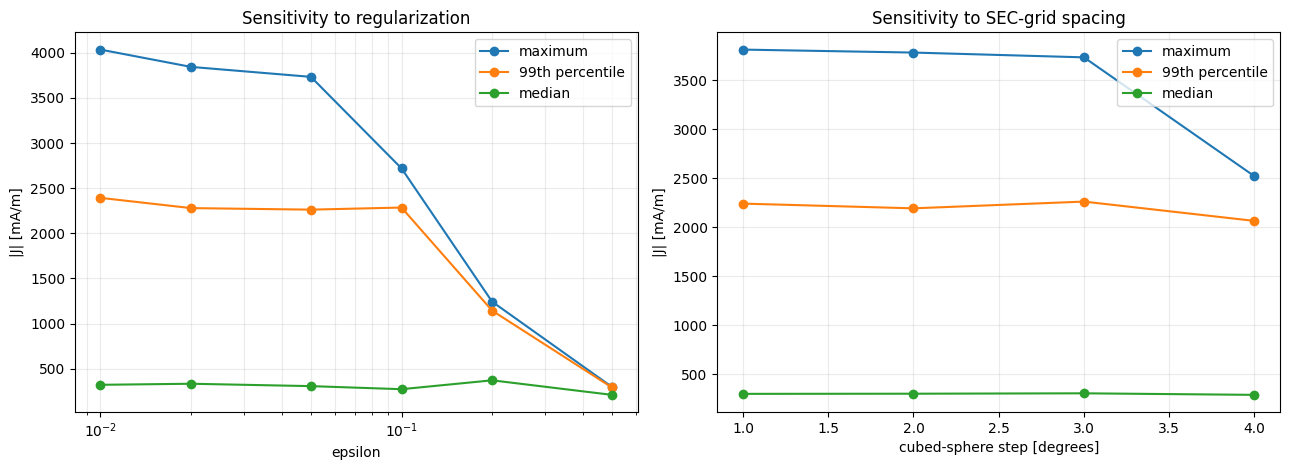

In [7]:
epsilon_records = []
baseline_current = fit.J[diagnostic_frame_index]
baseline_current_magnitude = np.hypot(
    baseline_current[:, 0],
    baseline_current[:, 1],
)
baseline_current_rms = np.sqrt(np.mean(baseline_current**2))

for epsilon in epsilon_values:
    epsilon_model = secs.SECS(sec_df_loc=fit.pole_loc)
    epsilon_model.fit(
        fit.obs_loc,
        fit.obs_B[diagnostic_frame_index : diagnostic_frame_index + 1],
        obs_std=fit.obs_std[
            diagnostic_frame_index : diagnostic_frame_index + 1
        ],
        epsilon=epsilon,
    )
    epsilon_current = east_north_current(
        epsilon_model,
        fit.eval_loc,
    )
    epsilon_current_magnitude = np.hypot(
        epsilon_current[:, 0],
        epsilon_current[:, 1],
    )
    valid_current = (
        np.isfinite(epsilon_current).all(axis=1)
        & np.isfinite(baseline_current).all(axis=1)
    )
    current_difference = (
        epsilon_current[valid_current]
        - baseline_current[valid_current]
    )
    epsilon_records.append(
        {
            'epsilon': epsilon,
            'max_mA_m': float(epsilon_current_magnitude.max() * 1000),
            'median_mA_m': float(
                np.median(epsilon_current_magnitude) * 1000
            ),
            'p99_mA_m': float(
                np.percentile(epsilon_current_magnitude, 99) * 1000
            ),
            'corr_vs_eps_0.05': float(
                np.corrcoef(
                    epsilon_current[valid_current].ravel(),
                    baseline_current[valid_current].ravel(),
                )[0, 1]
            ),
            'relative_rms_vs_eps_0.05': float(
                np.sqrt(np.mean(current_difference**2))
                / baseline_current_rms
            ),
        }
    )

epsilon_table = pd.DataFrame(epsilon_records)
print('J sensitivity to epsilon on the baseline SEC grid:')
print(epsilon_table.to_string(index=False))

coarse_records = []
for step in [1.0, 2.0, 3.0, 4.0]:
    if step == fit.step:
        grid_configuration = fit
    else:
        grid_configuration = SECSFit(
            DATA_PATH,
            max_missing=fit.max_missing,
            epsilon=fit.epsilon,
            step=step,
            lat_min=fit.lat_min,
            lat_max=fit.lat_max,
            lon_min=fit.lon_min,
            lon_max=fit.lon_max,
            iono_height=fit.iono_height,
            crop=fit.crop,
        )
        grid_configuration._make_observations()
        grid_configuration._make_grid()

    grid_model = secs.SECS(sec_df_loc=grid_configuration.pole_loc)
    grid_model.fit(
        grid_configuration.obs_loc,
        grid_configuration.obs_B[
            diagnostic_frame_index : diagnostic_frame_index + 1
        ],
        obs_std=grid_configuration.obs_std[
            diagnostic_frame_index : diagnostic_frame_index + 1
        ],
        epsilon=fit.epsilon,
    )
    grid_current = east_north_current(
        grid_model,
        grid_configuration.eval_loc,
    )
    grid_current_magnitude = np.hypot(
        grid_current[:, 0],
        grid_current[:, 1],
    )
    finite_grid_current = np.isfinite(grid_current_magnitude)
    coarse_records.append(
        {
            'step_degrees': step,
            'SEC_poles': grid_configuration.pole_loc.shape[0],
            'evaluation_points': grid_configuration.eval_loc.shape[0],
            'finite_vectors': int(finite_grid_current.sum()),
            'max_mA_m': float(
                np.nanmax(grid_current_magnitude) * 1000
            ),
            'median_mA_m': float(
                np.nanmedian(grid_current_magnitude) * 1000
            ),
            'p99_mA_m': float(
                np.nanpercentile(grid_current_magnitude, 99) * 1000
            ),
        }
    )

coarse_table = pd.DataFrame(coarse_records)
print()
print('J sensitivity to SEC-grid spacing at epsilon={:g}:'.format(fit.epsilon))
print(coarse_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for column, label in [
    ('max_mA_m', 'maximum'),
    ('p99_mA_m', '99th percentile'),
    ('median_mA_m', 'median'),
]:
    axes[0].plot(
        epsilon_table['epsilon'],
        epsilon_table[column],
        marker='o',
        label=label,
    )
axes[0].set_xscale('log')
axes[0].set_xlabel('epsilon')
axes[0].set_ylabel('|J| [mA/m]')
axes[0].set_title('Sensitivity to regularization')
axes[0].grid(alpha=0.25, which='both')
axes[0].legend()

for column, label in [
    ('max_mA_m', 'maximum'),
    ('p99_mA_m', '99th percentile'),
    ('median_mA_m', 'median'),
]:
    axes[1].plot(
        coarse_table['step_degrees'],
        coarse_table[column],
        marker='o',
        label=label,
    )
axes[1].set_xlabel('cubed-sphere step [degrees]')
axes[1].set_ylabel('|J| [mA/m]')
axes[1].set_title('Sensitivity to SEC-grid spacing')
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.tight_layout()
plt.show()
